# Task 3: Sales Prediction Model

**Dataset:** BigMart Sales (cleaned in Task 1)
**Objective:** Build and evaluate regression models that predict `item_outlet_sales` from item and outlet features, compare their performance, and tune the best one.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Load and Explore the Data
The readable cleaned file from Task 1 is used, because the new features need the item and outlet identifiers. The encoding is repeated inside this notebook so that every modelling step is visible.

In [2]:
df = pd.read_csv("../data/cleaned/bigmart_cleaned.csv")

print("Rows, columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())

# The target we want to predict
print("\nTarget: item_outlet_sales")
print(df["item_outlet_sales"].describe().round(1))

Rows, columns: (8523, 13)
Missing values: 0


,item_identifier,item_weight,item_fat_content,item_visibility,item_type,item_mrp,outlet_identifier,outlet_establishment_year,outlet_size,outlet_location_type,outlet_type,item_outlet_sales,sales_outlier_flag
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,False
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,False
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,False
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,False
4,NCD19,8.93,Non-Edible,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,False



Target: item_outlet_sales
count     8523.0
mean      2181.3
std       1706.5
min         33.3
25%        834.2
50%       1794.3
75%       3101.3
max      13087.0
Name: item_outlet_sales, dtype: float64


## 2. Feature Engineering
Date components, lag features and rolling averages need order dates, and this dataset has none, so features are built from the columns that exist:
- `outlet_age`: the data are from 2013, so age = 2013 minus the year the outlet opened.
- `mrp_per_weight`: price per unit of weight.
- `visibility_ratio`: the item's visibility in an outlet relative to its average visibility across all outlets.
- `mrp_band`: the price group (0 to 3). The histogram of `item_mrp` showed distinct price bands.

In [3]:
data = df.copy()

data["outlet_age"] = 2013 - data["outlet_establishment_year"]

data["mrp_per_weight"] = data["item_mrp"] / data["item_weight"]

# Visibility relative to the same item's average across outlets
data["visibility_ratio"] = data["item_visibility"] / data.groupby("item_identifier")["item_visibility"].transform("mean")

# Price bands: 0 = up to 70, 1 = 70-135, 2 = 135-200, 3 = above 200
data["mrp_band"] = pd.cut(data["item_mrp"], bins=[0, 70, 135, 200, 300], labels=False)

# Do the new features relate to sales?
new_cols = ["outlet_age", "mrp_per_weight", "visibility_ratio", "mrp_band", "item_outlet_sales"]
print(data[new_cols].corr()["item_outlet_sales"].round(2))

outlet_age           0.05
mrp_per_weight       0.38
visibility_ratio    -0.37
mrp_band             0.55
item_outlet_sales    1.00
Name: item_outlet_sales, dtype: float64


**Interpretation.** `mrp_band` (0.55) and `mrp_per_weight` (0.38) are associated with sales, but both are built from the price, so they largely repeat the information in `item_mrp`. `visibility_ratio` (-0.37) is more informative than raw visibility (-0.12): items shown more prominently than their own average tend to be in lower-selling outlets. `outlet_age` (0.05) has almost no association with sales.

## 3. Final Preparation and Encoding
- **Ordinal encoding:** `outlet_size` (Small 0, Medium 1, High 2) and `outlet_location_type` (Tier 1 0, Tier 2 1, Tier 3 2).
- **One-hot encoding:** `item_fat_content`, `item_type` and `outlet_type`.
- **Dropped:** `item_identifier` and `outlet_identifier` (labels, not features), `outlet_establishment_year` (replaced by `outlet_age`), and `sales_outlier_flag` (it is computed from the target and would leak the answer into the model).

In [4]:
data["outlet_size"] = data["outlet_size"].map({"Small": 0, "Medium": 1, "High": 2})
data["outlet_location_type"] = data["outlet_location_type"].map({"Tier 1": 0, "Tier 2": 1, "Tier 3": 2})

data = data.drop(columns=["item_identifier", "outlet_identifier",
                          "outlet_establishment_year", "sales_outlier_flag"])

data = pd.get_dummies(data, columns=["item_fat_content", "item_type", "outlet_type"],
                      drop_first=True, dtype=int)

print("Shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Non-numeric columns:", data.select_dtypes(exclude="number").columns.tolist())

Shape: (8523, 30)
Missing values: 0
Non-numeric columns: []


## 4. Train and Test Split
The data are split 80% for training and 20% for testing. The model learns only from the training rows, and its performance is judged on the test rows it has never seen. `random_state=42` makes the split repeatable.

In [5]:
X = data.drop(columns=["item_outlet_sales"])     # the features (inputs)
y = data["item_outlet_sales"]                    # the target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("Mean sales, train vs test:", round(y_train.mean()), round(y_test.mean()))

Training rows: 6818 | Test rows: 1705
Mean sales, train vs test: 2202 2097


## 5. Baseline Models
- **Mean baseline:** always predicts the average training sales. Any useful model must beat it.
- **Linear Regression:** a simple model that fits a straight-line relationship between the features and sales.

In [6]:
# A helper that scores a model, so every model is judged the same way
def evaluate(name, model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    return {
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test MAE": mean_absolute_error(y_test, pred_test),
    }

results = []

mean_model = DummyRegressor(strategy="mean").fit(X_train, y_train)
results.append(evaluate("Mean baseline", mean_model))

lr = LinearRegression().fit(X_train, y_train)
results.append(evaluate("Linear Regression", lr))

pd.DataFrame(results).round(3)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Mean baseline,0.000,-0.004,1651.990,1321.739
1,Linear Regression,0.559,0.579,1069.816,791.419


## 6. Random Forest
A Random Forest builds many decision trees on random parts of the data and averages their predictions. Unlike Linear Regression, it can capture non-linear patterns and interactions between features (for example price and outlet type together).

In [7]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

results.append(evaluate("Random Forest (default)", rf))
pd.DataFrame(results).round(3)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Mean baseline,0.000,-0.004,1651.990,1321.739
1,Linear Regression,0.559,0.579,1069.816,791.419
2,Random Forest (default),0.938,0.568,1083.990,760.020


## 7. Model Evaluation
- **MAE (mean absolute error):** the average size of the prediction error, in sales units.
- **RMSE (root mean squared error):** like MAE, but it penalises large errors more.
- **R²:** the share of the variation in sales the model explains (1 is perfect, 0 is no better than the average).
- Comparing **Train R²** with **Test R²** shows overfitting: a model that scores much higher on the training rows than on the test rows has memorised them.

In [8]:
comparison = pd.DataFrame(results).round(3)
comparison

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Mean baseline,0.000,-0.004,1651.990,1321.739
1,Linear Regression,0.559,0.579,1069.816,791.419
2,Random Forest (default),0.938,0.568,1083.990,760.020


**Interpretation.** The mean baseline has a test R² of -0.004 and an RMSE of 1,652, as expected from a model that always predicts the average. Linear Regression explains about 58% of the variation in sales (test R² 0.579), with an RMSE of 1,070 and an MAE of 791, which cuts the error by about 35% compared with the baseline. The default Random Forest fits the training data almost perfectly (train R² 0.938) but scores only 0.568 on the test set, which is a clear sign of overfitting. Its average error is slightly lower (MAE 760), but its RMSE (1,084) and R² are slightly worse, so the two models perform similarly on new data. Limiting the depth of the forest through tuning should reduce the overfitting.

## 8. Hyperparameter Tuning
The Random Forest overfits, so its settings are tuned with `RandomizedSearchCV`. It tries 25 random combinations of settings and scores each with 5-fold cross-validation on the training data only (the test set stays untouched). The main settings are `max_depth` and `min_samples_leaf`, which limit how closely each tree can fit the training data.

In [9]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8, 10, 12],
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": [0.5, 0.7, 1.0],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_grid,
    n_iter=25, cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42, n_jobs=-1)

search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Cross-validated RMSE:", round(-search.best_score_, 1))

best_rf = search.best_estimator_
results.append(evaluate("Random Forest (tuned)", best_rf))
pd.DataFrame(results).round(3)

Best settings: {'n_estimators': 100, 'min_samples_leaf': 40, 'max_features': 0.5, 'max_depth': 6}
Cross-validated RMSE: 1107.3


,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Mean baseline,0.000,-0.004,1651.990,1321.739
1,Linear Regression,0.559,0.579,1069.816,791.419
2,Random Forest (default),0.938,0.568,1083.990,760.020
3,Random Forest (tuned),0.603,0.612,1026.295,721.062


**Interpretation.** The default Random Forest overfitted: it scored 0.938 on the training data but only 0.568 on the test set. Tuning with `RandomizedSearchCV` (25 combinations, 5-fold cross-validation) limited how closely each tree can fit the training rows. The best settings were `n_estimators=100`, `max_depth=6`, `min_samples_leaf=40` and `max_features=0.5`, with a cross-validated RMSE of 1,107. The tuned model has similar train and test R² (0.603 and 0.612), so it generalises well, and it is the best model on every test metric (R² 0.612, RMSE 1,026, MAE 721). The improvement over Linear Regression is modest (RMSE about 4% lower), because the relationship between the features and sales is largely linear.

## 9. Feature Importance
The tuned Random Forest reports how much each feature contributed to its predictions.

item_mrp                         0.348
visibility_ratio                 0.231
mrp_band                         0.145
outlet_type_Supermarket Type3    0.102
mrp_per_weight                   0.065
outlet_age                       0.043
outlet_type_Supermarket Type1    0.038
outlet_size                      0.015
outlet_type_Supermarket Type2    0.003
item_visibility                  0.003
dtype: float64


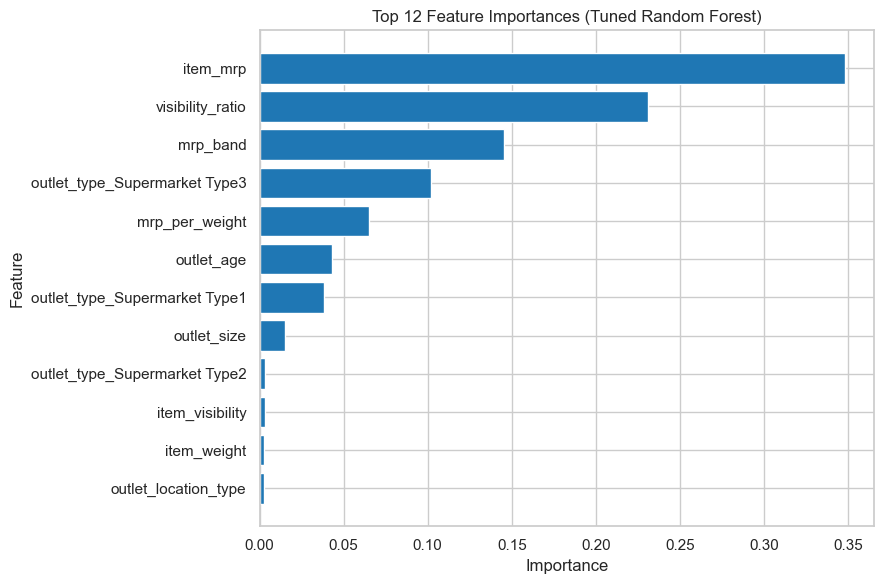

In [10]:
importance = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance.head(10).round(3))

top = importance.head(12).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color="#1f77b4")
plt.title("Top 12 Feature Importances (Tuned Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("../outputs/charts/model_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** Price drives the predictions: `item_mrp` (0.348), `mrp_band` (0.145) and `mrp_per_weight` (0.065) together account for about 56% of the importance, which matches the 0.57 correlation found in the EDA. The second most important feature is `visibility_ratio` (0.231), an item's visibility relative to its own average. This probably works as a stand-in for outlet type, because grocery stores show higher visibility and have the lowest sales. Outlet type is also important directly (Type3 0.102, Type1 0.038). Features such as `item_weight` and the raw `item_visibility` contribute almost nothing. Importance shows what the model relies on, not what causes sales.

## 10. Actual vs Predicted Values
The best model is chosen by the lowest test RMSE. In the plot, points on the diagonal line are perfect predictions.

Best model by test RMSE: Random Forest (tuned)


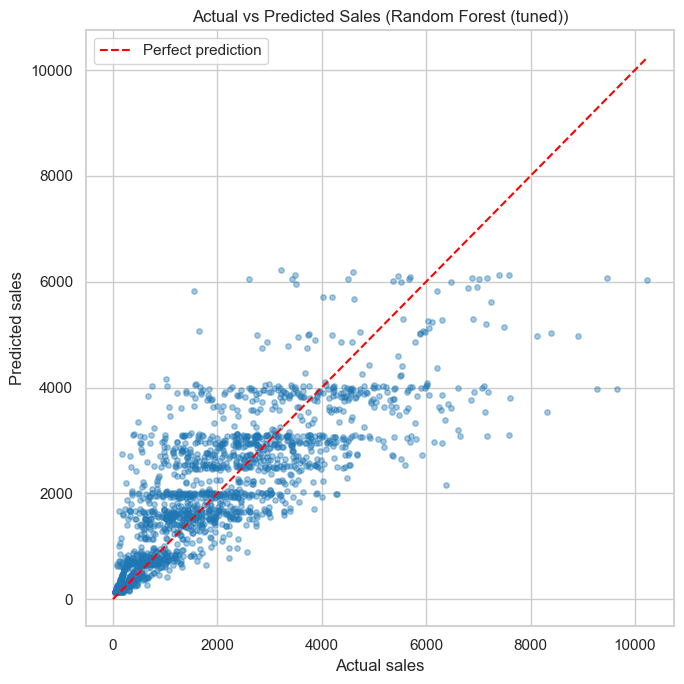

In [11]:
models = {"Mean baseline": mean_model, "Linear Regression": lr,
          "Random Forest (default)": rf, "Random Forest (tuned)": best_rf}

table = pd.DataFrame(results).sort_values("Test RMSE")
best_name = table.iloc[0]["Model"]
print("Best model by test RMSE:", best_name)

pred = models[best_name].predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred, alpha=0.4, s=15, color="#1f77b4")
lim = max(y_test.max(), pred.max())
plt.plot([0, lim], [0, lim], color="red", linestyle="--", label="Perfect prediction")
plt.title(f"Actual vs Predicted Sales ({best_name})")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/model_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** Points cluster around the red diagonal for sales below about 4,000, so the model predicts typical sales reasonably well. The model underestimates the highest sales: predictions rarely exceed about 6,000, even where actual sales reach 10,000. The horizontal bands appear because tree models predict in steps and not along a smooth line. This weakness at the top of the range is expected, because very high sales are rare and depend on factors that are not in the data.

In [12]:
final_table = pd.DataFrame(results).sort_values("Test RMSE").round(3)
final_table

,Model,Train R2,Test R2,Test RMSE,Test MAE
3,Random Forest (tuned),0.603,0.612,1026.295,721.062
1,Linear Regression,0.559,0.579,1069.816,791.419
2,Random Forest (default),0.938,0.568,1083.990,760.020
0,Mean baseline,0.000,-0.004,1651.990,1321.739


## 11. Summary, Business Interpretation and Limitations

### Model performance
Four models were compared on the same 20% test set (1,705 rows). The tuned Random Forest performed best, with an R² of 0.612, an RMSE of 1,026 and an MAE of 721. It explains about 61% of the variation in item sales, and its average error (721) is roughly a third of the average sales value (2,181). Hyperparameter tuning removed the overfitting of the default forest (test R² rose from 0.568 to 0.612).

### Business interpretation
- **Price and outlet type are the key drivers of sales.** Item price (MRP) and the type of outlet account for most of the model's predictive power, which agrees with the EDA findings.
- **The model can estimate expected sales** for an item in a given outlet, which helps with planning stock and setting targets for outlets.
- **Shelf visibility is not a lever by itself.** Its importance comes mostly from outlet type, so giving an item more shelf share should not be expected to raise its sales.

### Limitations
- The data cover a single year and have no dates, so lag features, rolling averages and forecasts of future periods were not possible. The model predicts sales for item-outlet combinations and not for future time periods.
- About 39% of the variation in sales is unexplained. Promotions, seasonality, competition and customer data are missing.
- The model underestimates the highest sales (above about 6,000).
- Some values were filled during cleaning (weights, outlet sizes), so predictions depend on those estimates.
- Results come from one 80/20 split, so small differences between models (for example Linear Regression and the tuned forest) should not be over-interpreted.

### Conclusion
A tuned Random Forest gives the most accurate predictions, but its advantage over the simple Linear Regression is small. A possible next step is a log transformation of the sales values to improve predictions of high sellers.